# Speed Dating Experiment — Exploratory Data Analysis

Data from experimental speed-dating events held in 2002–2004: every participant had a four-minute
"first date" with every participant of the opposite sex, then decided whether they would like to see
that partner again and rated the partner on six attributes.

**One row = one date seen from one participant.** Questionnaire answers (age, preferences, self-ratings...)
are repeated on every row of that participant, so questions *about people* are answered on one row per
participant, and questions *about dates* on all rows.

In [1]:
import sys
sys.path.insert(0, "../src")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from speed_dating.data import (ATTRIBUTE_NAMES, CAREER, FREQUENCY, GENDER, GOAL, RACE,
                               attribute_columns, load_data, normalize_to_100,
                               participants, scale_check)

pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 90

## 1. Meta analysis
### Samples and features

In [2]:
df = load_data()
people = participants(df)
print(f"{df.shape[0]} dates (rows), {df.shape[1]} features")
print(f"{len(people)} participants, {df.wave.nunique()} waves (events)")
df.head()

8378 dates (rows), 195 features
551 participants, 21 waves (events)


,iid,id,gender,idg,condtn,wave,round,position,positin1,order,partner,pid,match,int_corr,samerace,...,sinc2_3,intel2_3,fun2_3,amb2_3,shar2_3,attr3_3,sinc3_3,intel3_3,fun3_3,amb3_3,attr5_3,sinc5_3,intel5_3,fun5_3,amb5_3
0,1,1.0,0,1,1,1,10,7,NaN,4,1,11.0,0,0.14,0,...,NaN,NaN,NaN,NaN,NaN,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN
1,1,1.0,0,1,1,1,10,7,NaN,3,2,12.0,0,0.54,0,...,NaN,NaN,NaN,NaN,NaN,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN
2,1,1.0,0,1,1,1,10,7,NaN,10,3,13.0,1,0.16,1,...,NaN,NaN,NaN,NaN,NaN,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN
3,1,1.0,0,1,1,1,10,7,NaN,5,4,14.0,1,0.61,0,...,NaN,NaN,NaN,NaN,NaN,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN
4,1,1.0,0,1,1,1,10,7,NaN,7,5,15.0,1,0.21,0,...,NaN,NaN,NaN,NaN,NaN,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN


### Dtypes

In [3]:
df.dtypes.value_counts().rename("columns").to_frame()

,columns
float64,174
int64,13
object,8


In [4]:
df.select_dtypes("object").columns.tolist()

['field',
 'undergra',
 'mn_sat',
 'tuition',
 'from',
 'zipcode',
 'income',
 'career']

Only 8 columns are text. Most of them have an encoded numeric twin (`field` → `field_cd`,
`career` → `career_c`), and `income`, `tuition`, `mn_sat` are numbers stored as text
(`"69,487.00"`). All other features are numeric: codes, ratings, decisions.

### Missing values

columns without missing values: 13 of 195
columns with more than 50% missing: 59


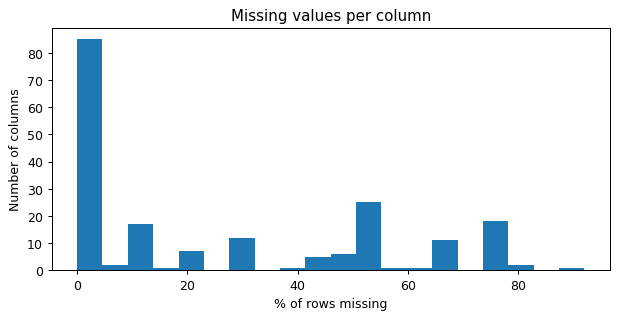

In [5]:
missing = df.isna().mean().sort_values(ascending=False)
print(f"columns without missing values: {(missing == 0).sum()} of {len(missing)}")
print(f"columns with more than 50% missing: {(missing > 0.5).sum()}")

ax = (missing * 100).plot.hist(bins=20, figsize=(8, 3.5), title="Missing values per column")
ax.set_xlabel("% of rows missing")
ax.set_ylabel("Number of columns")
plt.show()

In [6]:
(missing[missing > 0.5] * 100).round(1).rename("% missing").to_frame().T

,num_in_3,numdat_3,expnum,sinc7_2,amb7_2,shar7_2,attr7_2,intel7_2,fun7_2,amb5_3,attr7_3,sinc7_3,intel7_3,fun7_3,amb7_3,...,intel3_3,fun3_3,amb3_3,them_cal,fun3_s,intel3_s,sinc3_s,amb3_s,attr3_s,fun1_s,intel1_s,amb1_s,attr1_s,sinc1_s,shar1_s
% missing,92.0,82.1,78.5,76.7,76.7,76.4,76.3,76.3,76.3,75.9,75.9,75.9,75.9,75.9,75.9,...,52.6,52.6,52.6,52.6,52.3,52.3,52.3,52.3,52.3,51.1,51.1,51.1,51.1,51.1,51.1


Missing values come mostly from the follow-up questionnaires: `*_2` (the day after the event) and
`*_3` (3–4 weeks later) were filled in by only part of the participants. They are useless for
modeling and are not imputed.

## 2. Fields analysis
### About the people: gender, race, age, career

Counted per participant, not per date.

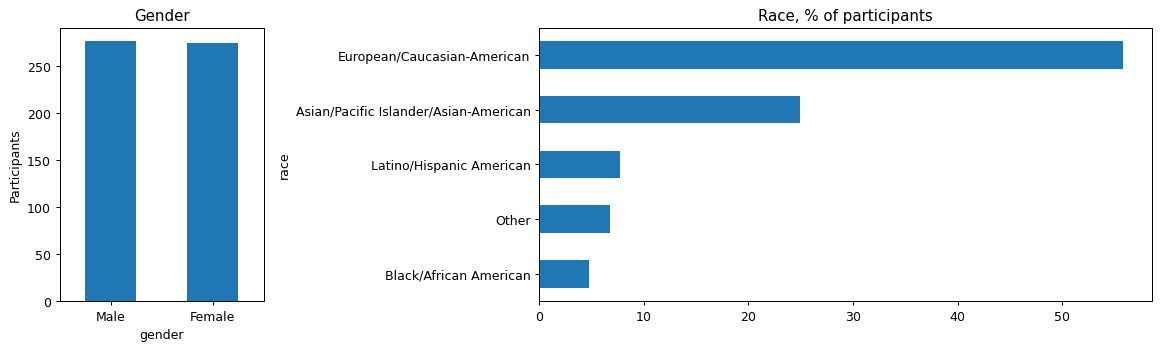

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1, 3]})
people.gender.map(GENDER).value_counts().plot.bar(ax=axes[0], rot=0, title="Gender")
people.race.map(RACE).value_counts(normalize=True).mul(100).plot.barh(ax=axes[1], title="Race, % of participants")
axes[0].set_ylabel("Participants")
axes[1].invert_yaxis()
plt.tight_layout()
plt.show()

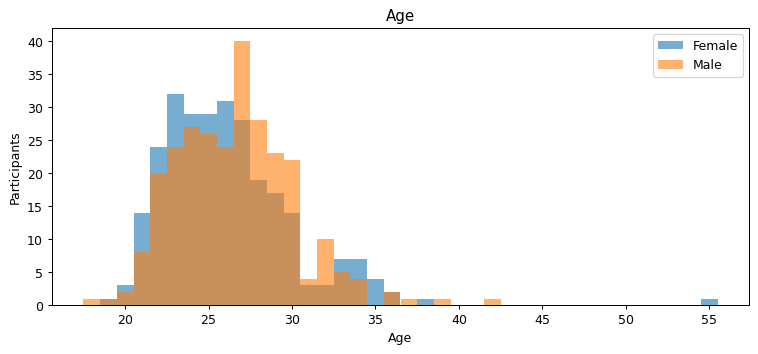

,count,mean,std,min,25%,50%,75%,max
gender,,,,,,,,
Female,269.0,26.1,4.0,19.0,23.0,26.0,28.0,55.0
Male,274.0,26.6,3.5,18.0,24.0,27.0,29.0,42.0


In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
bins = np.arange(17.5, 56.5, 1)
for code, name in GENDER.items():
    people.loc[people.gender == code, "age"].plot.hist(bins=bins, alpha=0.6, label=name, ax=ax)
ax.set_xlabel("Age")
ax.set_ylabel("Participants")
ax.set_title("Age")
ax.legend()
plt.show()
people.groupby(people.gender.map(GENDER)).age.describe().round(1)

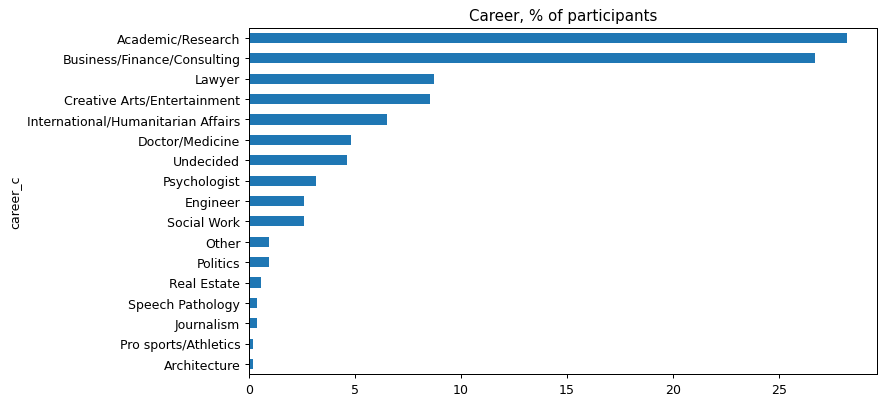

In [9]:
ax = people.career_c.map(CAREER).value_counts(normalize=True).mul(100).plot.barh(
    figsize=(9, 5), title="Career, % of participants")
ax.invert_yaxis()
plt.show()

In [10]:
career_by_race = pd.crosstab(people.career_c.map(CAREER), people.race.map(RACE), normalize="columns").mul(100).round(0)
career_by_race

race,Asian/Pacific Islander/Asian-American,Black/African American,European/Caucasian-American,Latino/Hispanic American,Other
career_c,,,,,
Academic/Research,29.0,20.0,31.0,17.0,22.0
Architecture,0.0,0.0,0.0,2.0,0.0
Business/Finance/Consulting,30.0,24.0,26.0,26.0,22.0
Creative Arts/Entertainment,5.0,8.0,10.0,5.0,16.0
Doctor/Medicine,10.0,4.0,3.0,7.0,3.0
Engineer,4.0,4.0,2.0,5.0,3.0
International/Humanitarian Affairs,1.0,8.0,7.0,14.0,8.0
Journalism,1.0,0.0,0.0,0.0,0.0
Lawyer,7.0,20.0,8.0,12.0,14.0


* Men and women are almost equally represented (274 / 277 participants).
* More than half of the participants are European/Caucasian-American (56%), a quarter are Asian (25%).
* Typical age is 23–29; women are slightly younger on average.
* More than half work in Academic/Research (28%) or Business/Finance/Consulting (27%) — the events were held
  for graduate and professional students.

### Dating: goal, how often they date, how often they go out

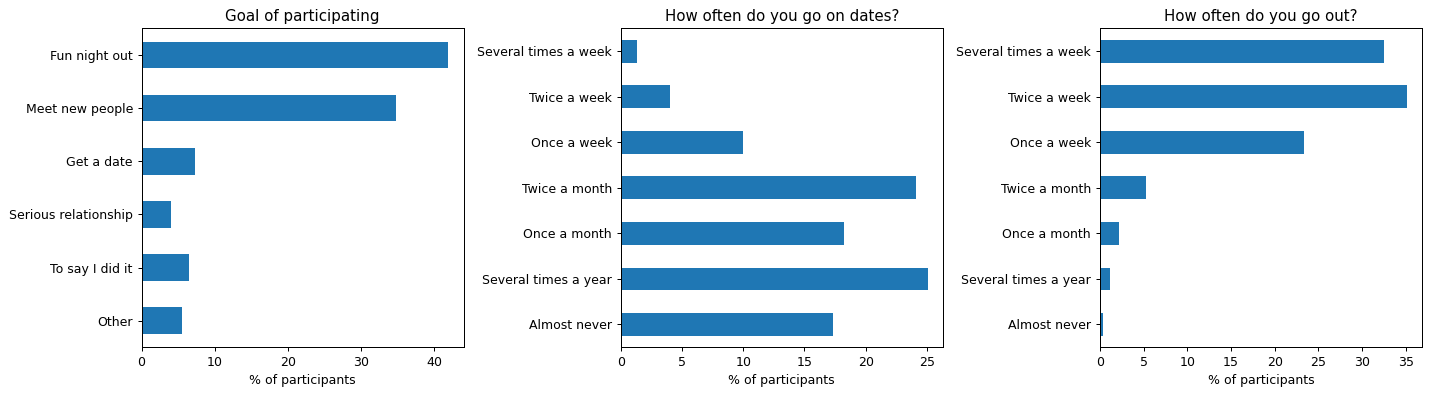

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (col, mapping, title) in zip(axes, [("goal", GOAL, "Goal of participating"),
                                            ("date", FREQUENCY, "How often do you go on dates?"),
                                            ("go_out", FREQUENCY, "How often do you go out?")]):
    counts = people[col].map(mapping).value_counts(normalize=True).mul(100)
    counts.reindex([v for v in mapping.values() if v in counts.index]).plot.barh(ax=ax, title=title)
    ax.invert_yaxis()
    ax.set_xlabel("% of participants")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

* The main goals are "fun night out" (42%) and "meet new people" (35%); only 4% came looking for a serious
  relationship.
* Most participants go out at least once a week, but go on dates much less often.

`goal` is a nominal variable, so a correlation coefficient with it has no meaning; a cross-table shows
the relation instead. `date` and `go_out` are ordinal (1 = most often, 7 = almost never), so Spearman
rank correlation fits them.

In [12]:
pd.crosstab(people.goal.map(GOAL), people.date.map(FREQUENCY), normalize="index").mul(100).round(0)[
    list(FREQUENCY.values())]

date,Several times a week,Twice a week,Once a week,Twice a month,Once a month,Several times a year,Almost never
goal,,,,,,,
Fun night out,2.0,4.0,14.0,25.0,19.0,21.0,15.0
Get a date,0.0,10.0,15.0,30.0,12.0,18.0,15.0
Meet new people,0.0,3.0,7.0,23.0,15.0,31.0,21.0
Other,3.0,3.0,7.0,23.0,17.0,23.0,23.0
Serious relationship,5.0,9.0,9.0,5.0,36.0,32.0,5.0
To say I did it,0.0,3.0,0.0,31.0,23.0,23.0,20.0


In [13]:
print("Spearman correlation, go_out vs date:", round(people[["go_out", "date"]].corr(method="spearman").iloc[0, 1], 2))
pd.crosstab(people.go_out.map(FREQUENCY), people.date.map(FREQUENCY)).reindex(
    index=list(FREQUENCY.values()), columns=list(FREQUENCY.values())).fillna(0).astype(int)

Spearman correlation, go_out vs date: 0.35


date,Several times a week,Twice a week,Once a week,Twice a month,Once a month,Several times a year,Almost never
go_out,,,,,,,
Several times a week,7,17,30,52,23,27,21
Twice a week,0,3,18,51,39,51,28
Once a week,0,2,6,26,28,37,28
Twice a month,0,0,0,2,4,10,13
Once a month,0,0,0,0,4,7,1
Several times a year,0,0,0,0,1,4,1
Almost never,0,0,0,0,0,0,2


* Participants who came for a serious relationship date less often than the others (mostly once a month or
  several times a year).
* People who go out more often also date more often, but the relation is moderate (Spearman ρ = 0.35):
  going out does not mean going on dates.

### Bi-variate analysis: "me–other" features

A match (`match = 1`) means both partners said yes. Each date appears twice in the data (once from each
side), so pairs are counted on the rows of male participants only.

In [14]:
pairs = df[df.gender == 1]
print(f"dates: {len(pairs)}, matches: {pairs.match.sum()}, match rate: {pairs.match.mean():.1%}")

dates: 4194, matches: 690, match rate: 16.5%


**Same race.**

In [15]:
same_race = pairs.groupby("samerace").match.agg(["count", "mean"]).rename(
    index={0: "different race", 1: "same race"}, columns={"count": "dates", "mean": "match rate"})
same_race["share of all matches"] = pairs.groupby("samerace").match.sum().values / pairs.match.sum()
same_race.style.format({"match rate": "{:.1%}", "share of all matches": "{:.1%}"})

,dates,match rate,share of all matches
samerace,,,
different race,2536,16.0%,59.0%
same race,1658,17.1%,41.0%


41% of all matches are same-race couples, but that is simply because 40% of all dates were same-race.
The match rate is almost the same: **17.1% for same race vs. 16.0% for different race** — race similarity
has nearly no effect on matching.

**Age difference.**

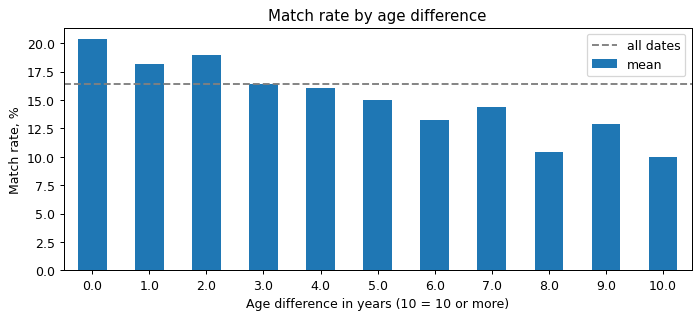

In [16]:
age_diff = (pairs.age - pairs.age_o).abs()
rate_by_diff = pairs.groupby(age_diff.clip(upper=10)).match.agg(["count", "mean"])
ax = rate_by_diff["mean"].mul(100).plot.bar(figsize=(9, 3.5), rot=0, title="Match rate by age difference")
ax.set_xlabel("Age difference in years (10 = 10 or more)")
ax.set_ylabel("Match rate, %")
ax.axhline(pairs.match.mean() * 100, color="gray", ls="--", label="all dates")
ax.legend()
plt.show()

The match rate falls steadily with the age difference: about 20% for partners of the same age, about 10%
for a difference of 8 years or more.

**Careers of the partners.**

In [17]:
career_o = pairs.pid.map(people.career_c)
pair_stats = (pd.DataFrame({"man": pairs.career_c.map(CAREER), "woman": career_o.map(CAREER),
                            "match": pairs.match})
              .dropna().groupby(["man", "woman"]).match.agg(dates="count", matches="sum", rate="mean"))
pair_stats[pair_stats.dates >= 50].sort_values("rate", ascending=False).style.format({"rate": "{:.1%}"})

Career combinations with at least 50 dates. The most frequent combinations (Academic/Research and
Business/Finance in any order) simply follow the most frequent careers and have an average match rate
(~17%). Above average: lawyer–lawyer (30%), business man – doctor woman (25%), business–lawyer and
business–business (22%). With 50–100 dates per combination these differences are suggestive, not proven.

## 3. Dating: what is important (by gender)

Questions on the six attributes: **Attractive, Sincere, Intelligent, Fun, Ambitious, Shared interests**.
Most waves split **100 points** between the attributes; waves 6–9 rated each attribute on a **1–10 scale**
instead (dataset description). Before comparing anything, every answer is checked by the sum of its points.

In [18]:
def check(suffix):
    cols = attribute_columns(suffix)
    kinds = scale_check(people, cols)
    return kinds, cols

summary_rows = {}
for suffix, question in [("1_1", "What you look for (sign-up)"), ("1_s", "What you look for (half-way)"),
                         ("4_1", "What your fellow men/women look for"), ("2_1", "What the opposite sex looks for")]:
    kinds, _ = check(suffix)
    summary_rows[f"{suffix}: {question}"] = kinds.kind.value_counts()
pd.DataFrame(summary_rows).T.fillna(0).astype(int)[["100 points", "100 points, wrong sum", "1-10 scale", "missing"]]

kind,100 points,"100 points, wrong sum",1-10 scale,missing
1_1: What you look for (sign-up),531,10,0,10
1_s: What you look for (half-way),211,17,53,270
4_1: What your fellow men/women look for,303,12,101,135
2_1: What the opposite sex looks for,523,20,0,8


* **Sign-up (`1_1`) and opposite sex (`2_1`)**: no 1–10 answers at all, although waves 6–9 were asked on
  the 1–10 scale — in this version of the dataset these answers were already converted to 100 points.
* **Half-way (`1_s`) and fellow men/women (`4_1`)**: both scales are present.
* A few answers of every question sum to a value close to, but not equal to 100.

Answers that do not sum to 100 points:

In [19]:
for suffix in ["1_1", "1_s", "4_1", "2_1"]:
    kinds, cols = check(suffix)
    wrong = kinds[kinds.kind == "100 points, wrong sum"]
    print(f"{suffix}: {len(wrong)} participants, sums {sorted(wrong['sum'].round(0).astype(int).unique())}")

1_1: 10 participants, sums [90, 95, 101, 110, 120, 148]
1_s: 17 participants, sums [80, 90, 95, 96, 97, 101, 105, 110, 120]
4_1: 12 participants, sums [80, 82, 90, 95, 98, 105, 110]
2_1: 20 participants, sums [80, 90, 95, 101, 105, 110, 112]


In [20]:
kinds, cols = check("1_s")
people.loc[kinds.kind == "1-10 scale", ["wave"] + cols].head(8)

,wave,attr1_s,sinc1_s,intel1_s,fun1_s,amb1_s,shar1_s
iid,,,,,,,
454,18,7.0,9.0,9.0,9.0,7.0,9.0
455,18,3.0,8.0,8.0,7.0,8.0,5.0
456,18,9.0,9.0,8.0,7.0,8.0,8.0
457,18,8.0,0.0,8.0,8.0,4.0,10.0
458,18,10.0,10.0,10.0,10.0,8.0,5.0
459,18,10.0,5.0,5.0,10.0,5.0,10.0
460,18,8.0,10.0,10.0,9.0,9.0,9.0
461,18,8.0,8.0,7.0,9.0,6.0,6.0


Wrong sums look like arithmetic slips of the participants. All answers are therefore normalized the same
way: **every answer is rescaled to shares that sum to 100**; for 1–10 answers a 0 (not a valid rating) is
first raised to 1.

In [21]:
def preferences(suffix):
    """Mean share of the 100 points per attribute and gender."""
    cols = attribute_columns(suffix)
    normalized = normalize_to_100(people, cols)
    means = normalized.groupby(normalized.gender.map(GENDER))[cols].mean()
    means.columns = [ATTRIBUTE_NAMES[c[:-len(suffix)]] for c in cols]
    return means

def plot_preferences(tables, title):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
    for ax, gender in zip(axes, ["Female", "Male"]):
        pd.DataFrame({name: t.loc[gender] for name, t in tables.items()}).plot.bar(ax=ax, rot=0, title=f"{title} — {gender}")
        ax.set_ylabel("Mean share of 100 points")
        ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

### What's important for you (what you look for in the opposite sex)
#### Sign-up questionnaire vs. half-way

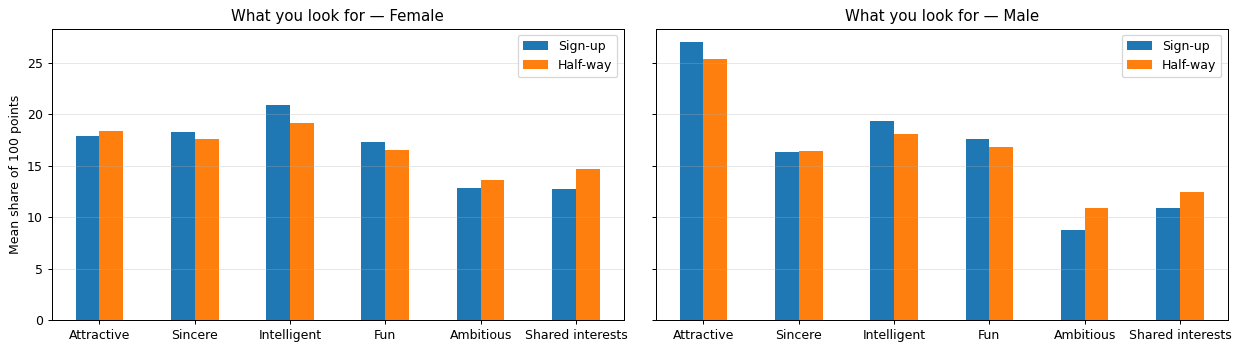

Sign-up                                                       \
       Attractive Sincere Intelligent   Fun Ambitious Shared interests   
gender                                                                   
Female       17.9    18.3        20.9  17.3      12.8             12.7   
Male         27.0    16.4        19.4  17.6       8.7             10.9   

         Half-way                                                       
       Attractive Sincere Intelligent   Fun Ambitious Shared interests  
gender                                                                  
Female       18.4    17.6        19.1  16.6      13.7             14.7  
Male         25.3    16.4        18.0  16.9      10.9             12.4

In [22]:
signup, halfway = preferences("1_1"), preferences("1_s")
plot_preferences({"Sign-up": signup, "Half-way": halfway}, "What you look for")
pd.concat({"Sign-up": signup, "Half-way": halfway}, axis=1).round(1)

* **Men** give the largest share to **attractiveness** (27 of 100 points); women split their points much
  more evenly, with **intelligence** first (21) and attractiveness only fourth (18).
* Women value ambition and shared interests more than men do.
* Half-way through the event the answers move only a little: men lower attractiveness (27 → 25),
  both genders give more to ambition and shared interests.

#### How much did the answer change?
Total absolute change of the six shares between sign-up and half-way (0 = same answer,
200 = completely different), for participants who answered both.

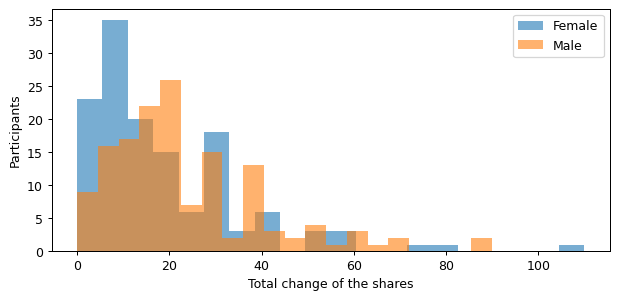

,count,mean,std,min,25%,50%,75%,max
gender,,,,,,,,
Female,135.0,19.1,17.2,0.0,7.8,13.0,30.0,110.0
Male,145.0,23.5,17.0,0.0,11.5,20.0,30.0,90.0


In [23]:
s1, ss = attribute_columns("1_1"), attribute_columns("1_s")
a = normalize_to_100(people, s1)[s1].to_numpy()
b = normalize_to_100(people, ss)[ss].to_numpy()
change = pd.Series(np.abs(a - b).sum(axis=1), index=people.index).dropna()
ax = change.groupby(people.gender.map(GENDER)).plot.hist(bins=20, alpha=0.6, legend=True, figsize=(8, 3.5))
plt.xlabel("Total change of the shares")
plt.ylabel("Participants")
plt.show()
change.groupby(people.gender.map(GENDER)).describe().round(1)

A typical participant moved about 10–15 of the 100 points (total change 20–30) — the answers are fairly
stable; men change their answers somewhat more than women.

### What's important for others of the same gender?
(What do you think MOST of your fellow men/women look for in the opposite sex?)

### What's important for others of the opposite gender?
(What do you think the opposite sex looks for in a date?)

Compared with what people say they look for themselves:

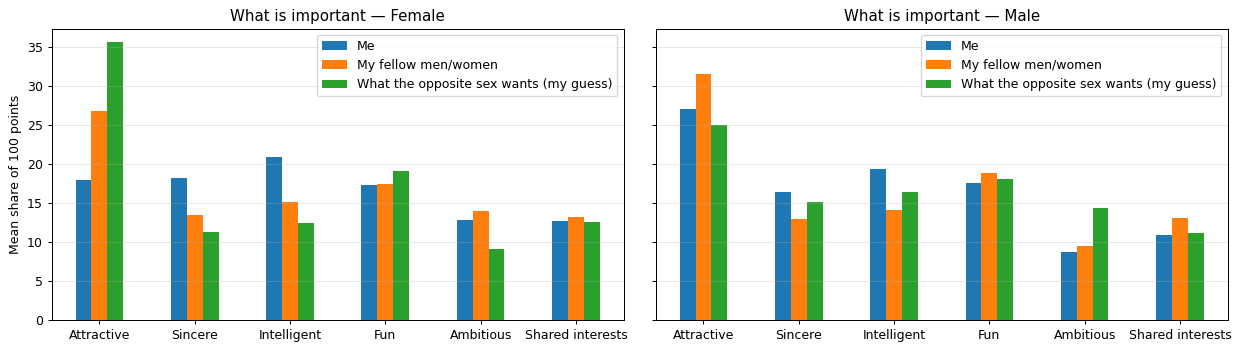

In [24]:
same_gender, opposite = preferences("4_1"), preferences("2_1")
plot_preferences({"Me": signup, "My fellow men/women": same_gender, "What the opposite sex wants (my guess)": opposite},
                 "What is important")

Reading the opposite sex: compare what women say men want with what men say they want, and vice versa.

In [25]:
guess_vs_real = pd.DataFrame({
    "Men want (men say)": signup.loc["Male"], "Men want (women guess)": opposite.loc["Female"],
    "Women want (women say)": signup.loc["Female"], "Women want (men guess)": opposite.loc["Male"],
}).round(1)
guess_vs_real

,Men want (men say),Men want (women guess),Women want (women say),Women want (men guess)
Attractive,27.0,35.5,17.9,24.9
Sincere,16.4,11.3,18.3,15.1
Intelligent,19.4,12.5,20.9,16.4
Fun,17.6,19.0,17.3,18.1
Ambitious,8.7,9.1,12.8,14.4
Shared interests,10.9,12.6,12.7,11.2


* Both genders believe that **others care about looks more than they do themselves**: women give
  attractiveness 18 points, but think other women give it 27 and men give it 36.
* Women overestimate how much men care about attractiveness (36 vs. 27 that men say) and underestimate
  sincerity and intelligence. Men overestimate attractiveness and ambition for women as well.
* This is about what people *say*. Whether the stated preferences match the actual decisions is
  checked in section 6.

## 4. Me vs. others

Five attributes rated on a 1–10 scale (there is no "shared interests" here):
* **How do I perceive myself?** — `*3_1`
* **How do I think others perceive me?** — `*5_1` (asked only from wave 10 on)
* **How do others actually perceive me?** — ratings by the partners on the night of the event (`*_o`),
  averaged per participant over all partners.

The follow-up questions `*7_2` / `*7_3` are missing for most participants, so partner ratings are used.

{'I think I am': 542, 'I think others see me': 314, 'Others actually see me': 551} participants


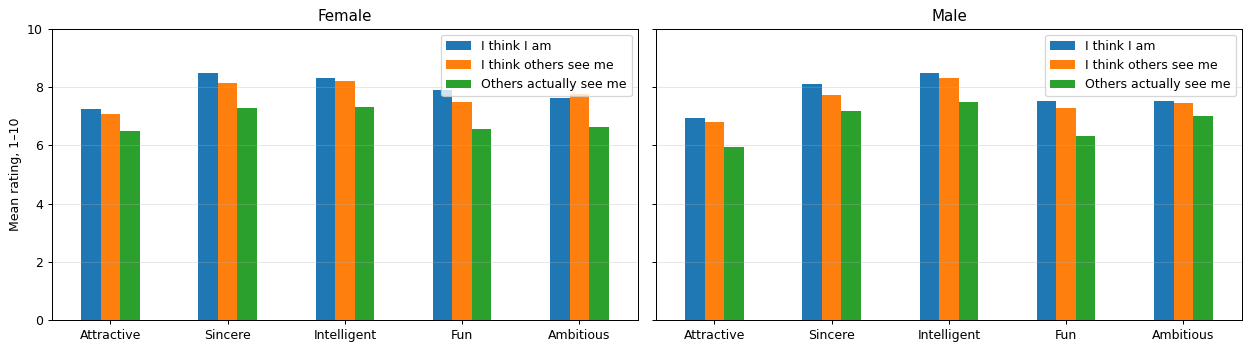

In [26]:
SELF = ["attr", "sinc", "intel", "fun", "amb"]
actual = df.groupby("iid")[[f"{a}_o" for a in SELF]].mean()
actual.columns = SELF
views = {
    "I think I am": people[attribute_columns("3_1", SELF)].set_axis(SELF, axis=1),
    "I think others see me": people[attribute_columns("5_1", SELF)].set_axis(SELF, axis=1),
    "Others actually see me": actual,
}
print({name: int(v.dropna().shape[0]) for name, v in views.items()}, "participants")

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, (code, gender) in zip(axes, GENDER.items()):
    ids = people.index[people.gender == code]
    table = pd.DataFrame({name: v.loc[v.index.intersection(ids)].mean() for name, v in views.items()})
    table.index = [ATTRIBUTE_NAMES[a] for a in SELF]
    table.plot.bar(ax=ax, rot=0, title=gender, ylim=(0, 10))
    ax.set_ylabel("Mean rating, 1–10")
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

* Both genders rate themselves higher than their partners rate them, on every attribute, by 0.5–1.3
  points; the largest gap is for **fun** and **attractiveness**.
* People expect others to see them almost exactly as they see themselves (blue ≈ orange) — the
  overestimation is not noticed.

### Do partners agree about a person?
For every participant: the standard deviation of the ratings given by their partners (0 = all partners
gave the same rating). Averaged per gender of the **rated** person. Lower = stronger agreement.

In [27]:
rated_std = df.groupby("iid")[[f"{a}_o" for a in ATTRIBUTE_NAMES]].std()
rated_std.columns = list(ATTRIBUTE_NAMES.values())
agreement = rated_std.groupby(people.gender.map(GENDER)).mean().round(2)
agreement.index = ["Women (rated by men)", "Men (rated by women)"]
agreement

,Attractive,Sincere,Intelligent,Fun,Ambitious,Shared interests
Women (rated by men),1.51,1.51,1.39,1.63,1.60,1.95
Men (rated by women),1.62,1.67,1.45,1.76,1.69,2.03


* Partners agree most about **intelligence** and least about **shared interests** — the latter depends on
  the pair, not only on the rated person.
* Women rate men less uniformly than men rate women (higher standard deviation on every attribute).

### How many partners do you expect to be interested in you vs. actual?
* `expnum` — "how many of the people you meet do you expect will be interested in dating you?"
  (sign-up, asked only in a few waves)
* `match_es` — "how many matches do you estimate you will get?" (end of the night)
* actual: number of partners who said yes (`sum of dec_o`) and number of matches (`sum of match`).

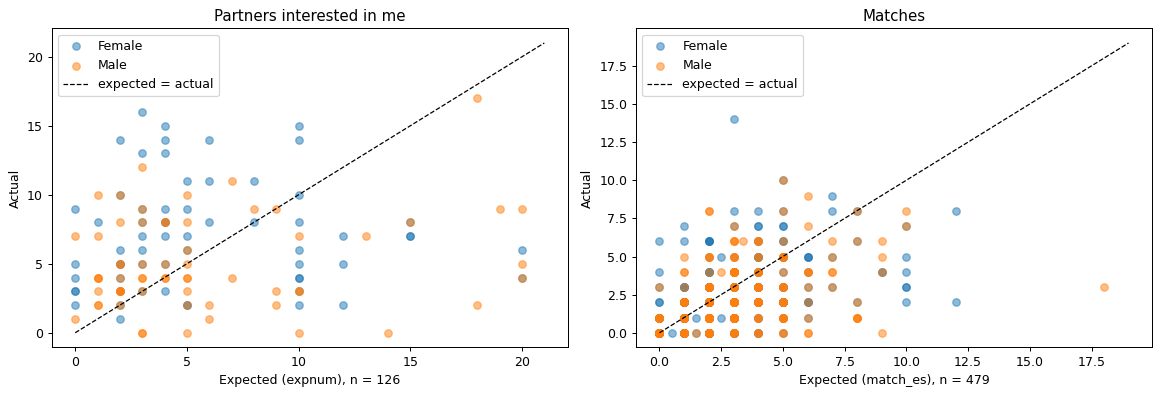

expnum_error              match_es_error             
              count  mean median          count  mean median
gender                                                      
Female           62 -1.21   -2.5            240  0.44    0.0
Male             64  0.89   -1.0            239  0.83    1.0

In [28]:
real = df.groupby("iid").agg(dates=("pid", "count"), yes_from_partners=("dec_o", "sum"), matches=("match", "sum"))
expect = people[["gender", "expnum", "match_es"]].join(real)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (guess, truth, label) in zip(axes, [("expnum", "yes_from_partners", "Partners interested in me"),
                                            ("match_es", "matches", "Matches")]):
    data = expect.dropna(subset=[guess])
    for code, gender in GENDER.items():
        part = data[data.gender == code]
        ax.scatter(part[guess], part[truth], alpha=0.5, label=gender)
    lim = max(data[guess].max(), data[truth].max()) + 1
    ax.plot([0, lim], [0, lim], "k--", lw=1, label="expected = actual")
    ax.set_xlabel(f"Expected ({guess}), n = {len(data)}")
    ax.set_ylabel("Actual")
    ax.set_title(label)
    ax.legend()
plt.tight_layout()
plt.show()

(expect.assign(expnum_error=expect.expnum - expect.yes_from_partners, match_es_error=expect.match_es - expect.matches)
 .groupby(expect.gender.map(GENDER))[["expnum_error", "match_es_error"]].agg(["count", "mean", "median"]).round(2))

Error = expected − actual. Expectations are only loosely related to reality (the points are spread far
from the diagonal). On average **women underestimate** how many partners will be interested in them,
while **men overestimate** both the interest and the number of matches.

## 5. Effects of the experiment set-up (% match)

The question is about the **share** of dates that ended with a match, not the number of matches:
small date orders and station numbers exist in every wave, large ones only in big waves, so raw counts
would simply follow the number of dates.

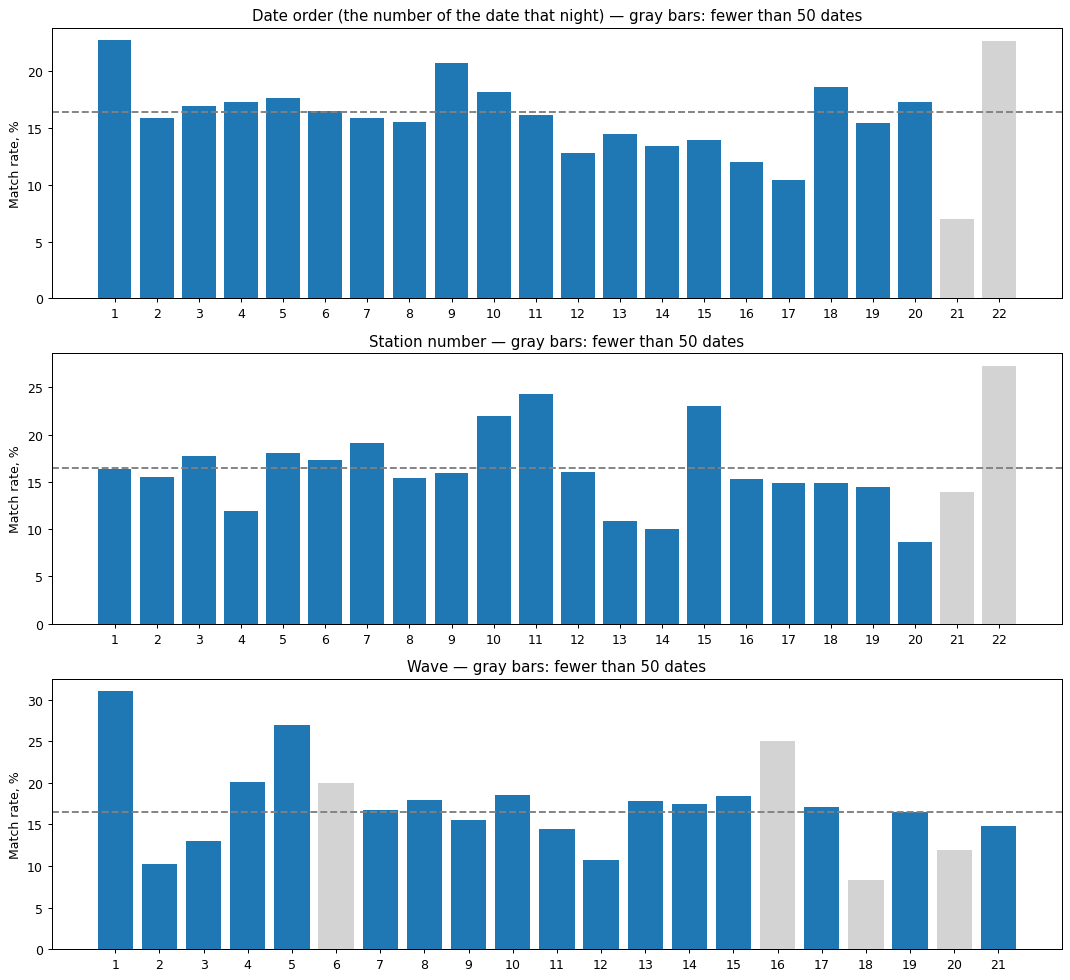

In [29]:
def match_rate(column):
    return pairs.groupby(column).match.agg(dates="count", match_rate="mean")

fig, axes = plt.subplots(3, 1, figsize=(12, 11))
for ax, (column, title) in zip(axes, [("order", "Date order (the number of the date that night)"),
                                      ("position", "Station number"),
                                      ("wave", "Wave")]):
    rate = match_rate(column)
    ax.bar(rate.index, rate.match_rate * 100, color=np.where(rate.dates < 50, "lightgray", "C0"))
    ax.axhline(pairs.match.mean() * 100, color="gray", ls="--")
    ax.set_title(title + " — gray bars: fewer than 50 dates")
    ax.set_ylabel("Match rate, %")
    ax.set_xticks(rate.index)
plt.tight_layout()
plt.show()

In [30]:
match_rate("wave").sort_values("match_rate", ascending=False).head(6).style.format({"match_rate": "{:.1%}"})

,dates,match_rate
wave,,
1,100,31.0%
5,100,27.0%
16,48,25.0%
4,324,20.1%
6,25,20.0%
10,81,18.5%


* **Date order**: the first date of the night has the highest match rate (23%); late dates (12–17) are
  below average — a sign of fatigue. The very last orders exist only in a few big waves.
* **Station number**: no station is consistently "lucky"; the differences (10–24%) are within what is
  expected for 100–300 dates per station.
* **Waves**: waves 1 and 5 have the highest match rates (31% and 27%, 100 dates each). Waves 6, 16, 18
  and 20 are too small to compare.

## 6. Towards predicting a decision
### Features: me / other / other-on-me

For one row (one date of participant `iid` with partner `pid`):

| Group | Features |
|---|---|
| **me** | my sign-up profile: gender, age, race, field, career, goal, dating habits, activities, what I look for (`*1_1`), how I rate myself (`*3_1`), how I think others see me (`*5_1`); my scorecard of the partner: `attr`, `sinc`, `intel`, `fun`, `amb`, `shar`, `like`, `prob`, `met` |
| **other** | the partner's sign-up profile (looked up by `pid`); `age_o`, `race_o`, `pf_o_*` (partner's preferences) |
| **other-on-me** | the partner's scorecard of me: `attr_o`, `sinc_o`, `intel_o`, `fun_o`, `amb_o`, `shar_o`, `like_o`, `prob_o`, `met_o` |
| **targets** | `dec` — my decision; `dec_o` — the partner's decision; `match` = `dec` AND `dec_o` |

### Features vs. decisions
Correlation of every feature with `dec` and `dec_o`, computed on all dates (point-biserial correlation:
Pearson correlation with a 0/1 variable).

In [31]:
groups = {
    "my scorecard of the partner": ["attr", "sinc", "intel", "fun", "amb", "shar", "like", "prob"],
    "partner's scorecard of me": ["attr_o", "sinc_o", "intel_o", "fun_o", "amb_o", "shar_o", "like_o", "prob_o"],
    "how I rate myself": attribute_columns("3_1", SELF),
    "what I look for": attribute_columns("1_1"),
}
normalized = normalize_to_100(df, attribute_columns("1_1"))
rows = []
for group, cols in groups.items():
    for col in cols:
        rows.append((group, col, normalized[col].corr(df.dec), normalized[col].corr(df.dec_o)))
corr = pd.DataFrame(rows, columns=["group", "feature", "my decision (dec)", "partner's decision (dec_o)"]).set_index(["group", "feature"])
corr.style.format("{:.2f}").background_gradient(cmap="RdBu_r", vmin=-0.7, vmax=0.7)

* **My decision depends on my scorecard of the partner**: how much I liked the partner (`like`, 0.51),
  attractiveness (0.49), fun (0.41) and shared interests (0.40). Sincerity, intelligence and ambition —
  which people *say* are important — correlate much less (0.18–0.22).
* Symmetrically, **the partner's decision depends on the partner's scorecard of me**.
* What I say about myself (self-ratings, what I look for) has almost **no correlation** with either decision
  (|r| ≤ 0.09).

The course version of this analysis averaged the decisions per rating value first and correlated the
averages (10 points per feature), which gave misleadingly high values (e.g. 0.91 for self-rated
attractiveness vs. the partner's decision). On individual dates the same correlation is 0.09.

### Which features are (not) important?

* **Not usable**: follow-up questionnaires (`*_2`, `*_3`) and other columns missing for a large part of
  the participants (`income`, `tuition`, `mn_sat`, `expnum`...).
* **Administrative**: `id`, `idg`, `round`, `position`, `positin1`, `order`, `partner` — they describe the
  organization of the event, not the people. `iid`, `pid` and `wave` are used only to join partners and
  to split the data.
* **Duplicates**: text fields with encoded twins (`field` → `field_cd`, `career` → `career_c`);
  `match` = `dec` AND `dec_o`; `samerace` follows from `race` and `race_o`.
* **Strong**: the scorecards filled in right after the date — but they are known only after the date.

The next notebooks build classifiers on three feature sets: own profile only, both profiles
(known before the date), and both profiles + both scorecards.